# Train and check Pokémon BST predictions

BST is the sum of six base stats. We compare predicting BST directly with predicting a change from a stage/rarity median.

Use project Python 3.14.8 kernel. Existing datasets stay unchanged. No downloads.

A **fold** is one train/check round: train on earlier generations, predict the next generation, then compare predictions with known BST. We use four rounds, checking generations 6–9. All four help choose settings and model, so none is an untouched final test.

New runs choose models using **ordinary Pokémon**: everyone except Ultra Beasts and Paradox Pokémon. This includes ordinary legendary Pokémon. Special groups still receive predictions and separate scores. Original stage and rarity labels stay unchanged.

Compare CatBoost native, CatBoost ordinal, LightGBM and XGBoost. Each learns either BST directly or a correction to the training median. A stage-median-only model provides a simple reference.

In [1]:
# Resolve project root before package imports. Works from root or notebooks/.
import os
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pyproject.toml").is_file() and (p / "pokeml").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook inside the ml_pokemon project")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if sys.version_info[:2] != (3, 14):
    raise RuntimeError("Select project Python 3.14.8 kernel (.pokemon)")
print(f"Project: {PROJECT_ROOT} | Python: {sys.version.split()[0]} | Kernel: {sys.executable}")


Project: /Users/pano/Library/Mobile Documents/com~apple~CloudDocs/coding/portfolio/ml_pokemon | Python: 3.14.8 | Kernel: /Users/pano/venv/pokemon/.pokemon/bin/python


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from pokeml.pipeline.workflow import WorkflowConfig, run_workflow, load_historical_workflow_result
from pokeml.models.deployment import PokemonPredictor
sns.set_theme(style="whitegrid", context="notebook")
from pokeml.evaluation.groups import grouped_metrics, pooled_group_summary, save_historical_group_report

def readable_scores(table):
    view = table.copy()
    if "evaluation_scope" in view:
        view["evaluation_scope"] = view.evaluation_scope.map({
            "all": "All Pokémon", "ordinary": "Ordinary Pokémon",
            "ultra_beast": "Ultra Beasts", "paradox": "Paradox Pokémon"})
    return view.rename(columns={
        "evaluation_scope": "Group", "population": "Dataset", "model": "Model",
        "generation": "Check generation", "n_validation": "Pokémon checked",
        "MAE": "Average error (MAE)", "RMSE": "Large-error score (RMSE)",
        "bias": "Average actual minus predicted", "folds": "Train/check rounds"})


## 1. Choose settings

Default mode displays saved results. **It does not train.** To train, set `REUSE_RUN = None`, run this cell, then run section 2.

`TUNE_ITERATIONS = 0` uses starting settings. A positive number tries that many settings per model/method. `SELECTION_SCOPE = "ordinary"` ignores special groups when choosing settings and model; `"all"` includes everyone.

Every training set still includes all eligible earlier-generation Pokémon. Final model learns from generations 1–9, including both special groups. Size is in metres/kilograms. Stage and rarity are supplied assumptions.

In [3]:
TUNE_ITERATIONS = 0
REUSE_RUN = Path("artifacts/workflow/pokemon_tuned_60_v1")
SELECTION_SCOPE = "ordinary"  # Or "all"; applies to NEW training runs.
config = WorkflowConfig(tune_iterations=TUNE_ITERATIONS, selection_scope=SELECTION_SCOPE)
pokemon = pd.read_csv(config.training_csv)
announcements = pd.read_csv(config.prediction_csv)
display(announcements)
print("Next cell reads saved results." if REUSE_RUN is not None else "Next cell STARTS TRAINING.")

,name,type_1,type_2,rarity,stage,shape,color,height,weight
0,browt,grass,NaN,regular,s1c3,legs,yellow,0.3,3.5
1,pombon,fire,NaN,regular,s1c3,quadruped,red,0.4,6.7
2,gecqua,water,NaN,regular,s1c3,quadruped,blue,0.3,4.3


Next cell reads saved results.


## 2. Train and check models

**Training happens in next cell at `run_workflow(config)`, only when `REUSE_RUN=None`.**

Each round starts fresh. Learn stage/rarity median and feature rules from training rows only. Direct models learn BST. Correction models learn `actual BST − training median`; predictions add that median back.

Predict every Pokémon in check generation. Calculate errors separately for all, ordinary, Ultra Beast and Paradox Pokémon. Do not use check targets to stop training early.

Gen-7 Ultra Beasts enter training in rounds checking generations 8 and 9. No training records are removed.

In [4]:
if REUSE_RUN is not None:
    if TUNE_ITERATIONS != 0:
        raise ValueError("Set REUSE_RUN=None to request a new tuning run")
    result = load_historical_workflow_result(REUSE_RUN)
    print("Historical saved results; source differs from current package. No fitting performed.")
else:
    result = run_workflow(config)
print(f"Run: {result.run_directory.resolve()}")
print(f"Saved winner: {result.selected_model}")
if result.tuning_results is not None:
    display(result.tuning_results)
print("Selection group used by this run:", result.selection_scope)
if REUSE_RUN is not None:
    group_report = save_historical_group_report(result.run_directory)
    print("Separate breakdown of old predictions:", group_report)

Historical saved results; source differs from current package. No fitting performed.
Run: /Users/pano/Library/Mobile Documents/com~apple~CloudDocs/coding/portfolio/ml_pokemon/artifacts/workflow/pokemon_tuned_60_v1
Saved winner: direct_cat_native


,model,development_MAE,development_RMSE,folds,n_validation,trials,best_trial_id,default_won,default_MAE,elapsed_seconds,params
0,direct_cat_native,30.868513,41.875693,4,433,60,57,False,33.657700,241.354516,"{""depth"": 6, ""iterations"": 1600, ""l2_leaf_reg""..."
1,direct_cat_ordinal,31.316285,42.986544,4,433,60,26,False,33.823392,202.846312,"{""depth"": 5, ""iterations"": 400, ""l2_leaf_reg"":..."
2,direct_light_gbm,30.909540,42.938081,4,433,60,43,False,32.457744,18.449654,"{""colsample_bytree"": 1.0, ""fit_uncertainty"": t..."
3,direct_xgboost,32.050184,44.739150,4,433,60,49,False,33.205129,27.204632,"{""colsample_bytree"": 0.7, ""fit_uncertainty"": t..."
4,correction_cat_native,33.077702,50.596872,4,433,60,33,False,33.663022,249.226612,"{""depth"": 6, ""iterations"": 800, ""l2_leaf_reg"":..."
5,correction_cat_ordinal,33.412224,50.777904,4,433,60,25,False,34.109325,205.694693,"{""depth"": 6, ""iterations"": 1600, ""l2_leaf_reg""..."
6,correction_light_gbm,32.533059,51.090571,4,433,60,43,False,32.818350,25.958053,"{""colsample_bytree"": 1.0, ""fit_uncertainty"": t..."
7,correction_xgboost,32.338246,51.175504,4,433,60,51,False,32.993846,34.259690,"{""colsample_bytree"": 0.7, ""fit_uncertainty"": t..."


Selection group used by this run: all


Separate breakdown of old predictions: artifacts/evaluation/special_groups/pokemon_tuned_60_v1_6181db697d83


## 3. Compare errors across four rounds

**MAE** means average absolute error in BST points. Lower is better. **RMSE** gives large mistakes more weight. **Average signed error** is actual minus predicted BST: positive means predictions are too low.

Every checked Pokémon has equal weight. We add absolute errors across rounds and divide by total checked Pokémon; we do not average four MAEs equally.

Current ordinary counts are 72, 95, 133 and 102: **402 Pokémon**. Empty groups show zero records and no score. Historical breakdown below reuses old predictions and does not change original winner.

,check_generation,training_count,all_check_count,training_generations,ordinary_check_count
0,6,649,72,1–5,72
1,7,721,106,1–6,95
2,8,827,133,1–7,133
3,9,960,122,1–8,102


,Dataset,Model,Group,Average error (MAE),Large-error score (RMSE),Pokémon checked,generations,Train/check rounds,Average actual minus predicted
16,default_species,direct_cat_native,All Pokémon,31.260,42.383,376,4,4,6.348
24,default_species,direct_light_gbm,All Pokémon,31.581,43.539,376,4,4,5.381
20,default_species,direct_cat_ordinal,All Pokémon,32.286,44.293,376,4,4,5.319
28,default_species,direct_xgboost,All Pokémon,32.755,45.761,376,4,4,7.000
12,default_species,correction_xgboost,All Pokémon,32.764,52.578,376,4,4,2.627
...,...,...,...,...,...,...,...,...,...
51,selected_forms,correction_xgboost,Ultra Beasts,79.434,88.340,11,1,1,79.238
47,selected_forms,correction_light_gbm,Ultra Beasts,79.735,90.177,11,1,1,79.735
39,selected_forms,correction_cat_native,Ultra Beasts,82.213,90.063,11,1,1,82.213
43,selected_forms,correction_cat_ordinal,Ultra Beasts,84.609,92.865,11,1,1,84.609


,Dataset,Check generation,Model,Group,Pokémon checked,Average error (MAE),Large-error score (RMSE),Average actual minus predicted
8,default_species,6,correction_light_gbm,All Pokémon,72,29.435,37.914,12.521
32,default_species,6,stage_median,All Pokémon,72,29.931,43.339,5.569
20,default_species,6,direct_cat_ordinal,All Pokémon,72,30.943,38.452,12.816
12,default_species,6,correction_xgboost,All Pokémon,72,31.353,40.831,13.517
16,default_species,6,direct_cat_native,All Pokémon,72,31.425,40.187,15.945
...,...,...,...,...,...,...,...,...
270,selected_forms,9,direct_cat_native,Ultra Beasts,0,NaN,NaN,NaN
274,selected_forms,9,direct_cat_ordinal,Ultra Beasts,0,NaN,NaN,NaN
278,selected_forms,9,direct_light_gbm,Ultra Beasts,0,NaN,NaN,NaN
282,selected_forms,9,direct_xgboost,Ultra Beasts,0,NaN,NaN,NaN


Plot below uses ALL Pokémon; group scores are in tables above.


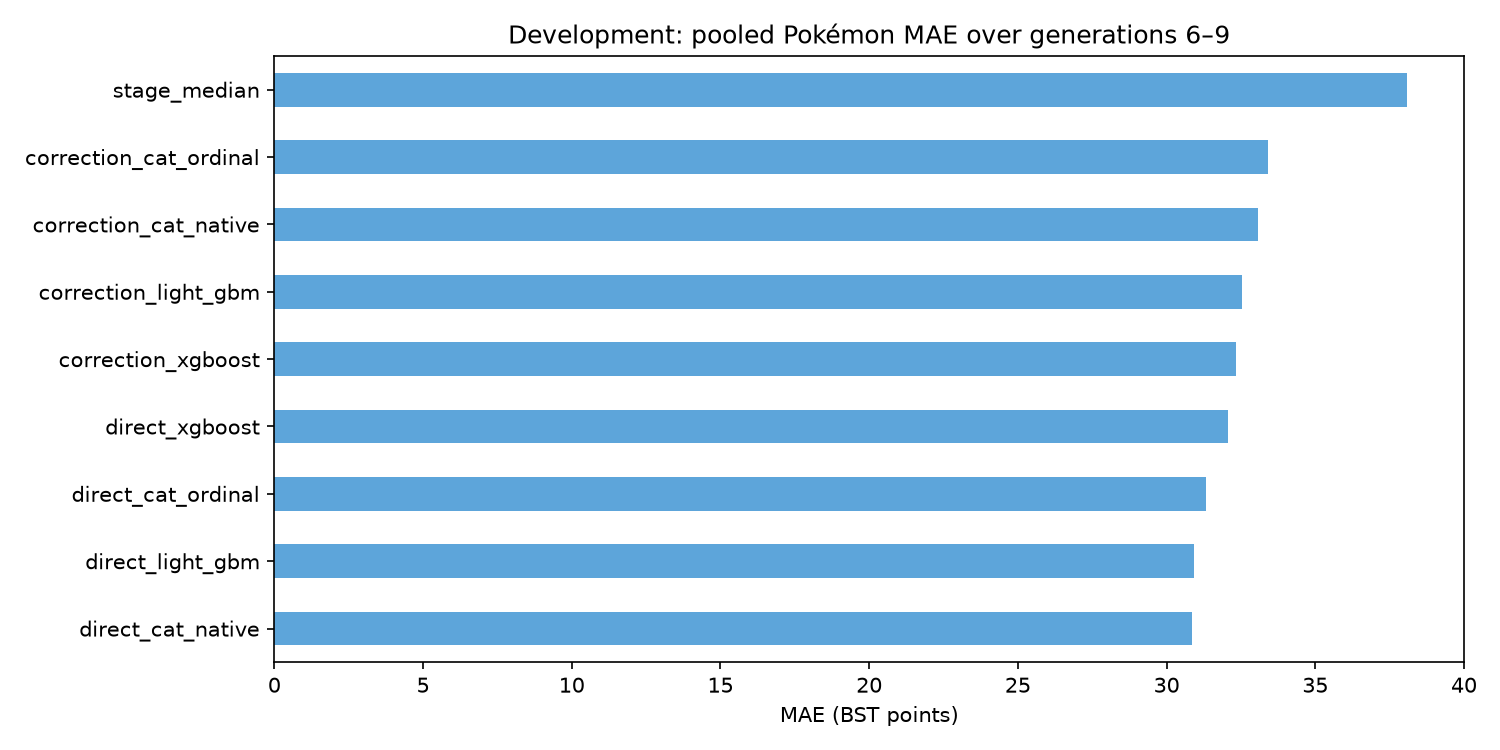

In [5]:
folds = result.development_metrics.query("population == 'selected_forms' and model == 'stage_median'")[["generation", "n_train", "n_validation"]].copy()
folds["training_generations"] = folds.generation.map(lambda g: f"1–{g - 1}")
ordinary = result.evaluation_metrics.query("population == 'selected_forms' and model == 'stage_median' and evaluation_scope == 'ordinary'")
folds = folds.merge(ordinary[["generation", "n_validation"]].rename(columns={"n_validation": "ordinary_check_count"}), on="generation")
display(folds.rename(columns={"generation": "check_generation", "n_train": "training_count", "n_validation": "all_check_count"}))
display(readable_scores(result.evaluation_summary.sort_values(["population", "evaluation_scope", "MAE"]).round(3)))
display(readable_scores(result.evaluation_metrics.sort_values(["population", "generation", "evaluation_scope", "MAE"]).round(3)))
print("Plot below uses ALL Pokémon; group scores are in tables above.")
display(Image(filename=str(result.run_directory / "plots/development_comparison.png")))

## 4. Check generation 9 and special groups

Generation 9 has 122 rows: 102 ordinary and 20 Paradox. Generation 7 has 106: 95 ordinary and 11 Ultra Beasts. Poipole and Naganadel are Ultra Beasts even though their stages are not single.

Group scores combine by counts:

`all MAE = (ordinary count × ordinary MAE + special count × special MAE) / all count`

For RMSE, square each group RMSE, weight by counts, divide by total count, then take square root. MAE has no square root.

Splitting groups changes reporting, not predictions. These scores help choose models; they are not an independent final test.

,Dataset,Check generation,Model,Group,Pokémon checked,Average error (MAE),Large-error score (RMSE),Average actual minus predicted
276,selected_forms,9,direct_light_gbm,All Pokémon,122,30.355,41.902,4.643
268,selected_forms,9,direct_cat_native,All Pokémon,122,31.604,41.408,4.371
252,selected_forms,9,correction_cat_native,All Pokémon,122,31.989,44.776,6.397
272,selected_forms,9,direct_cat_ordinal,All Pokémon,122,32.195,43.022,3.991
260,selected_forms,9,correction_light_gbm,All Pokémon,122,32.336,45.043,5.524
264,selected_forms,9,correction_xgboost,All Pokémon,122,32.890,45.708,5.108
256,selected_forms,9,correction_cat_ordinal,All Pokémon,122,34.006,47.662,5.865
280,selected_forms,9,direct_xgboost,All Pokémon,122,34.588,48.015,6.127
284,selected_forms,9,stage_median,All Pokémon,122,39.557,52.728,4.934
253,selected_forms,9,correction_cat_native,Ordinary Pokémon,102,22.920,31.424,-1.833


count     MAE
model                  known_family               
correction_cat_native  False           112  31.203
                       True             10  40.793
correction_cat_ordinal False           112  33.594
                       True             10  38.627
correction_light_gbm   False           112  31.951
                       True             10  36.647
correction_xgboost     False           112  31.965
                       True             10  43.259
direct_cat_native      False           112  30.344
                       True             10  45.724
direct_cat_ordinal     False           112  30.926
                       True             10  46.407
direct_light_gbm       False           112  29.358
                       True             10  41.517
direct_xgboost         False           112  33.862
                       True             10  42.724
stage_median           False           112  38.536
                       True             10  51.000

Count-weighted group MAE = 31.60; all-Pokémon MAE = 31.60
Count-weighted squared group RMSE = 41.41; all-Pokémon RMSE = 41.41


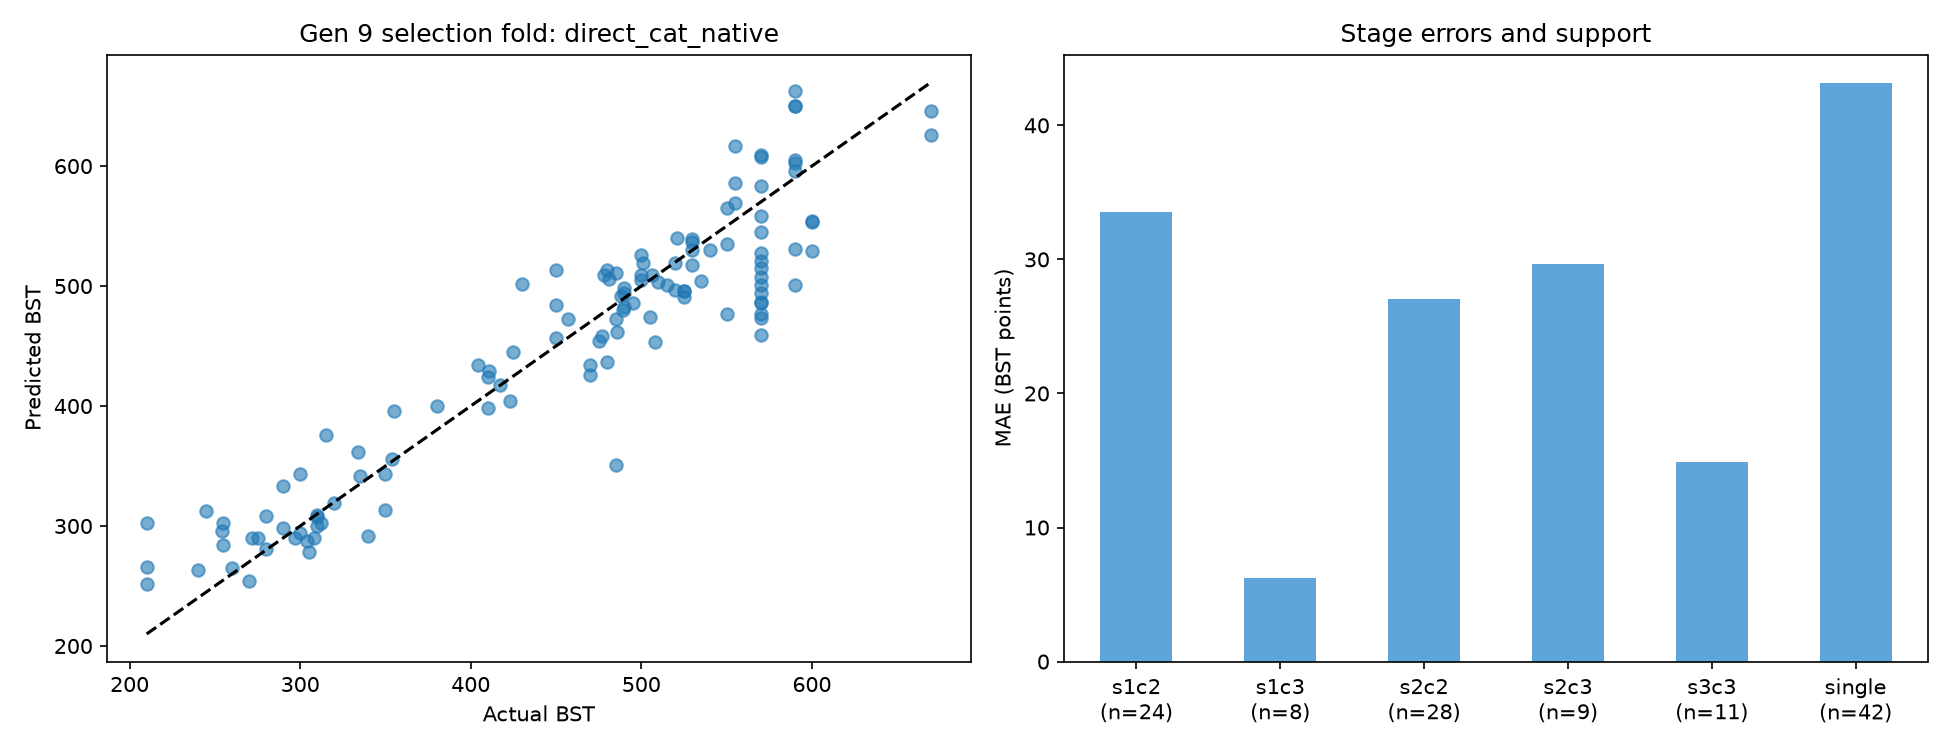

In [6]:
display(readable_scores(result.evaluation_metrics.query("population == 'selected_forms' and generation == 9").sort_values(["evaluation_scope", "MAE"]).round(3)))
primary = result.validation_details.query("population == 'selected_forms'")
display(primary.groupby(["model", "known_family"]).agg(count=("name", "size"), MAE=("absolute_error", "mean")).round(3))
chosen = result.evaluation_metrics.query("population == 'selected_forms' and generation == 9 and model == @result.selected_model")
all_score = chosen.query("evaluation_scope == 'all'").iloc[0]
parts = chosen.query("evaluation_scope != 'all' and n_validation > 0")
combined_mae = (parts.MAE * parts.n_validation).sum() / parts.n_validation.sum()
combined_rmse = ((parts.RMSE ** 2 * parts.n_validation).sum() / parts.n_validation.sum()) ** .5
print(f"Count-weighted group MAE = {combined_mae:.2f}; all-Pokémon MAE = {all_score.MAE:.2f}")
print(f"Count-weighted squared group RMSE = {combined_rmse:.2f}; all-Pokémon RMSE = {all_score.RMSE:.2f}")
assert abs(combined_mae - all_score.MAE) < 1e-8
assert abs(combined_rmse - all_score.RMSE) < 1e-8
display(Image(filename=str(result.run_directory / "plots/selected_validation.png")))

## 5. Inspect stage errors and corrections

Compare errors within stages, with and without special designs. Ordinary singles may still be hard to predict.

Reference table below learned from generations 1–8. Buckets with fewer than five examples use rarity median, then overall median. Final saved model learns new medians from generations 1–9. Positive correction adds BST to reference.

,rarity,stage,median,count,uses_fallback
0,legendary,s1c2,385.0,3,True
1,legendary,s1c3,200.0,1,True
2,legendary,s2c2,570.0,3,True
3,legendary,s2c3,400.0,1,True
4,legendary,s3c3,680.0,2,True
5,legendary,single,600.0,77,False
6,regular,s1c2,315.0,213,False
7,regular,s1c3,300.0,108,False
8,regular,s2c2,485.0,236,False
9,regular,s2c3,405.0,109,False


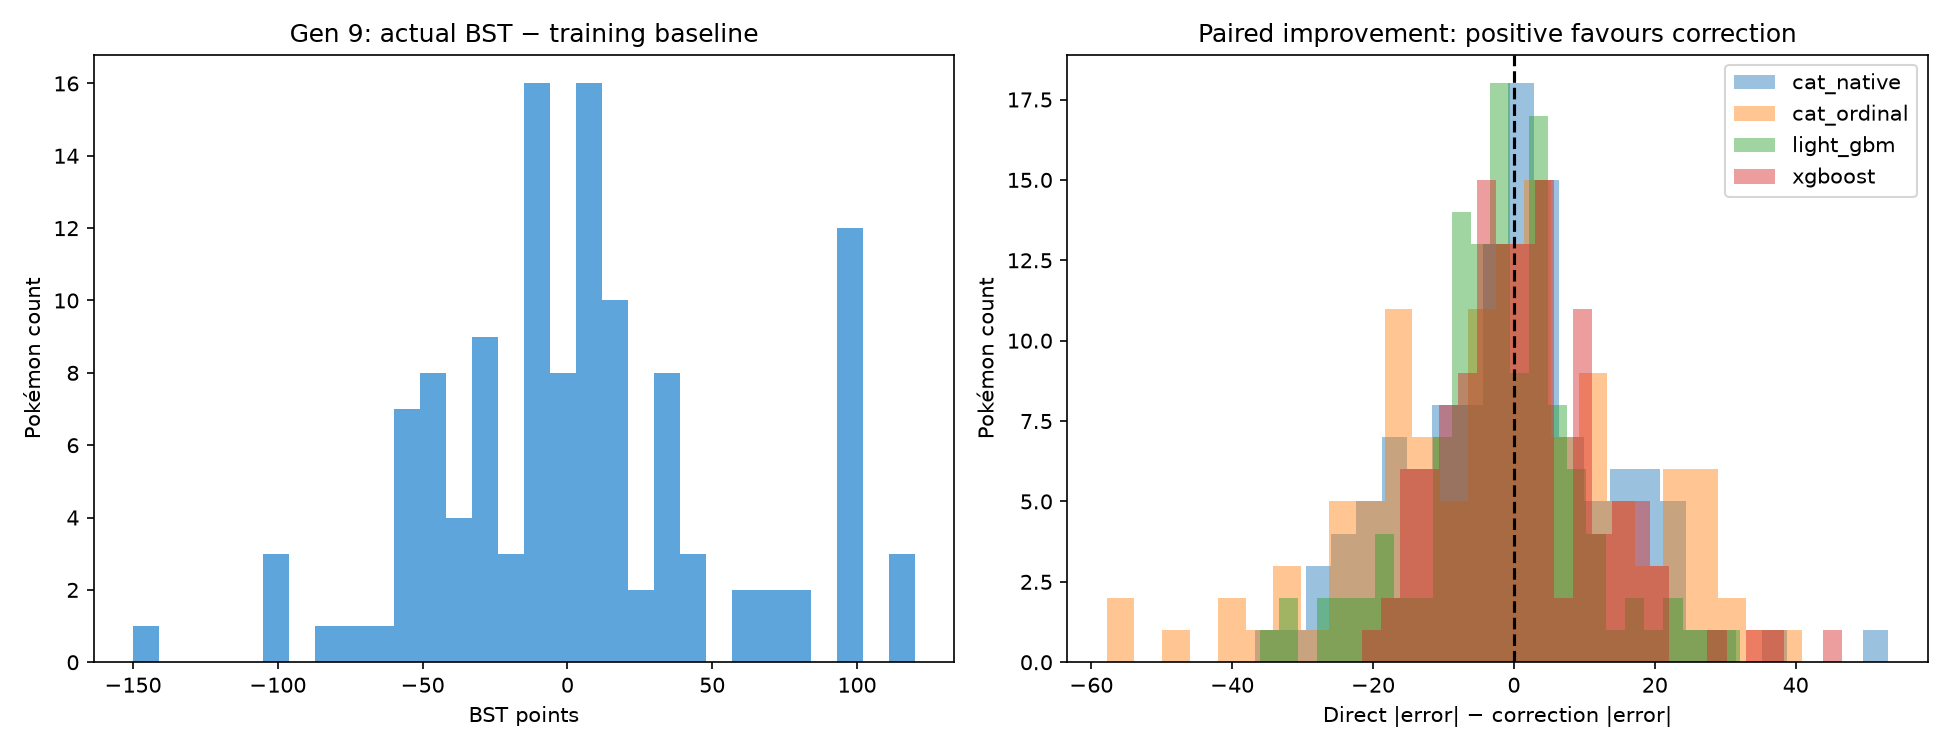

,Dataset,Check generation,Model,rarity,stage,Group,Pokémon checked,Average error (MAE),Large-error score (RMSE),Average actual minus predicted
1512,selected_forms,7,correction_cat_native,legendary,s1c2,All Pokémon,2,221.217,233.055,-221.217
1513,selected_forms,7,correction_cat_native,legendary,s1c2,Ordinary Pokémon,2,221.217,233.055,-221.217
1514,selected_forms,7,correction_cat_native,legendary,s1c2,Ultra Beasts,0,NaN,NaN,NaN
1515,selected_forms,7,correction_cat_native,legendary,s1c2,Paradox Pokémon,0,NaN,NaN,NaN
1516,selected_forms,7,correction_cat_native,legendary,s1c3,All Pokémon,1,376.476,376.476,-376.476
...,...,...,...,...,...,...,...,...,...,...
2515,selected_forms,9,stage_median,regular,s3c3,Paradox Pokémon,0,NaN,NaN,NaN
2516,selected_forms,9,stage_median,regular,single,All Pokémon,24,70.500,81.211,64.417
2517,selected_forms,9,stage_median,regular,single,Ordinary Pokémon,10,25.200,30.796,10.600
2518,selected_forms,9,stage_median,regular,single,Ultra Beasts,0,NaN,NaN,NaN


,name,stage,baseline_bst,actual_correction_bst,correction_bst,pred_bst,actual_bst,absolute_error
939,iron_bundle,single,470.0,100.0,-16.33,453.67,570,116.33
934,brute_bonnet,single,470.0,100.0,-14.14,455.86,570,114.14
933,scream_tail,single,470.0,100.0,-8.24,461.76,570,108.24
953,roaring_moon,single,470.0,120.0,13.13,483.13,590,106.87
954,iron_valiant,single,470.0,120.0,15.54,485.54,590,104.46
972,terapagos,single,600.0,-150.0,-50.04,549.96,450,99.96
937,sandy_shocks,single,470.0,100.0,0.29,470.29,570,99.71
942,iron_moth,single,470.0,100.0,0.68,470.68,570,99.32
935,flutter_mane,single,470.0,100.0,7.38,477.38,570,92.62
940,iron_hands,single,470.0,100.0,12.35,482.35,570,87.65


In [7]:
display(result.baseline_table)
display(Image(filename=str(result.run_directory / "plots/correction_diagnostics.png")))
display(readable_scores(result.evaluation_stage_errors.query("population == 'selected_forms' and generation in [7, 9]").round(3)))
correction_rows = primary.query("model == 'correction_light_gbm'")
display(correction_rows[["name", "stage", "baseline_bst", "actual_correction_bst",
                         "correction_bst", "pred_bst", "actual_bst", "absolute_error"]].nlargest(20, "absolute_error").round(2))

### Biggest mistakes

Small training groups and later-added evolutions can cause mistakes. For example, current stage labels include evolutions introduced after original Pokémon. Keep these cases visible.

In [8]:
development_rows = pd.read_csv(result.run_directory / "development_details.csv")
worst = development_rows.query("population == 'selected_forms' and model == 'correction_light_gbm'")
display(worst.nlargest(12, "absolute_error")[["name", "generation", "rarity", "stage",
       "baseline_source", "baseline_bst", "actual_bst", "pred_bst", "absolute_error"]].round(2))

,name,generation,rarity,stage,baseline_source,baseline_bst,actual_bst,pred_bst,absolute_error
1457,cosmog,7,legendary,s1c3,rarity,600.0,200,579.55,379.55
1476,meltan,7,legendary,s1c2,rarity,600.0,300,606.40,306.40
1414,wishiwashi,7,regular,single,stage_rarity,460.0,175,437.00,262.00
2614,kubfu,8,legendary,s1c2,rarity,600.0,385,605.92,220.92
1458,cosmoem,7,legendary,s2c3,rarity,600.0,400,603.32,203.32
2607,duraludon,8,regular,s1c2,stage_rarity,315.0,535,350.01,184.99
1471,poipole,7,regular,s1c2,stage_rarity,316.0,420,287.05,132.95
1463,pheromosa,7,regular,single,stage_rarity,460.0,570,438.88,131.12
519,spewpa,6,regular,s2c3,stage_rarity,405.0,213,338.21,125.21
1466,kartana,7,regular,single,stage_rarity,460.0,570,445.39,124.61


## 6. Predict new Pokémon

Load final saved model and supply announcement attributes. This step predicts only: no training, tuning, cleaning or downloads.

Final model learned from generations 1–9. Its predictions on those training rows would not be validation scores. For direct models, displayed correction is simply prediction minus reference median.

In [9]:
predictor = PokemonPredictor.load(result.release_directory)
predictions = predictor.predict(announcements)
display(predictions.round(2))
assert predictions.name.tolist() == announcements.name.tolist()
display(pd.read_csv(result.run_directory / "release_baseline_table.csv"))
fig, ax = plt.subplots(figsize=(9, 4))
plot = predictions.set_index("name")[["baseline_bst", "pred_bst"]]
plot.plot.bar(ax=ax, color=["#B8C4D0", "#5DA5DA"], rot=0)
ax.set(title=f"All-history release: {result.selected_model}", xlabel="", ylabel="BST")
fig.tight_layout()
plt.show()

,name,stage,baseline_bst,correction_bst,pred_bst,baseline_source,baseline_count,prediction_mode,knowledge_variance,data_variance,predictive_std,model_version
0,browt,s1c3,300.0,-37.12,262.88,stage_rarity,116,direct,18.13,545.80,23.75,pokemon_tuned_60_v1/direct_cat_native
1,pombon,s1c3,300.0,4.76,304.76,stage_rarity,116,direct,0.48,217.97,14.78,pokemon_tuned_60_v1/direct_cat_native
2,gecqua,s1c3,300.0,6.64,306.64,stage_rarity,116,direct,1.22,159.28,12.67,pokemon_tuned_60_v1/direct_cat_native


,rarity,stage,median,count
0,legendary,s1c2,385.0,3
1,legendary,s1c3,200.0,1
2,legendary,s2c2,570.0,3
3,legendary,s2c3,400.0,1
4,legendary,s3c3,680.0,2
5,legendary,single,590.0,95
6,regular,s1c2,308.0,237
7,regular,s1c3,300.0,116
8,regular,s2c2,487.0,264
9,regular,s2c3,405.0,118


/var/folders/h8/kn6p4vt50_v066v_y6f9qp9w0000gn/T/ipykernel_16634/764755139.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. Inspect a correction model

This saved example learned from generations 1–8. It shows reference plus correction separately; it is not necessarily selected model.

In [10]:
correction_predictor = PokemonPredictor.load(
    result.run_directory / "evaluation_models/correction_light_gbm")
display(correction_predictor.predict(announcements).round(2))

,name,stage,baseline_bst,correction_bst,pred_bst,baseline_source,baseline_count,prediction_mode,lower_80,upper_80,quantile_crossed,model_version
0,browt,s1c3,300.0,-18.51,281.49,stage_rarity,108,correction,253.93,308.18,False,pokemon_tuned_60_v1/evaluation/correction_ligh...
1,pombon,s1c3,300.0,12.31,312.31,stage_rarity,108,correction,297.51,317.96,False,pokemon_tuned_60_v1/evaluation/correction_ligh...
2,gecqua,s1c3,300.0,10.12,310.12,stage_rarity,108,correction,271.92,311.94,False,pokemon_tuned_60_v1/evaluation/correction_ligh...


## 8. Check saved settings and limitations

Saved record shows data/code hashes, versions, selected settings and selection group. Historical winner used all Pokémon. New default uses ordinary Pokémon.

Current stats and evolution chains may reveal information unavailable when Pokémon first appeared. Future work: historical inputs, family-separated tests, stage uncertainty and reliable prediction ranges.

In [11]:
manifest = json.loads((result.release_directory / "manifest.json").read_text())
display(pd.Series(manifest))
print("CLI: python -m pokeml.cli model predict-release --release-directory", result.release_directory,
      "--input-path datasets/new_pokes.csv --output-path artifacts/predictions/my_predictions.csv")

training_csv                                               datasets/pkdx_min.csv
training_sha256                2c6785a018140d20ce85b349fa1c244bdadf4c03eccb54...
prediction_csv                                            datasets/new_pokes.csv
prediction_sha256              ea78f963ceb4a76d324a6faace8f501272c286d38a94cc...
source_sha256                  82be212780ebd6d6f93a99492b7a76d03946c99e32734b...
python                                                                    3.14.8
packages                       {'pandas': '3.0.6', 'numpy': '2.5.4', 'scikit-...
feature_steps                                                      [initial_tag]
selected_model                                                 direct_cat_native
selection                      Pooled individual-Pokémon MAE across validatio...
selection_weighting                                                      pokemon
validation_generations                                              [6, 7, 8, 9]
separate_holdout            

CLI: python -m pokeml.cli model predict-release --release-directory artifacts/workflow/pokemon_tuned_60_v1/release --input-path datasets/new_pokes.csv --output-path artifacts/predictions/my_predictions.csv
